# Partial PMP 2026

## Zvinca Bianca




### Ex. 1
#### a)

In [4]:

import numpy as np
from hmmlearn.hmm import CategoricalHMM

model = CategoricalHMM(n_components=4, init_params="")

model.startprob_ = np.array([0.25, 0.25, 0.25, 0.25]) # pozitia initiala este uniform distribuita deci avem probabilitati egale

model.transmat_ = np.array([
    [0.2, 0.4, 0.0, 0.4],
    [0.4, 0.2, 0.4, 0.0],
    [0.0, 0.4, 0.2, 0.4],
    [0.4, 0.0, 0.4, 0.2]
])

model.emissionprob_ = np.array([
    [0.7, 0.2, 0.1],
    [0.2, 0.6, 0.2],
    [0.1, 0.3, 0.6],
    [0.5, 0.2, 0.3]
])

secv = np.array([[0], [1], [2], [2], [0]]) # consideram red 0 green 1 si blue 2

prob, rez = model.decode(secv, algorithm="viterbi")

rez += 1

print("Cea mai probabila secventa de camere:", rez)
print("Probabilitatea comuna:", np.exp(prob))

Cea mai probabila secventa de camere: [1 2 3 4 1]
Probabilitatea comuna: 0.000338688


#### b) In aceasta situatie, trebuie sa modificam matricea de tranzitie astfel incat probabilitatea ca ronotul sa ramna pe aceeasi pozitie sa fie 0.0 in loc de 0.2, iar pe pozitiile vecine probabilitatile sa fie 0.5:

In [6]:
model.transmat_ = np.array([
    [0.0, 0.5, 0.0, 0.5],
    [0.5, 0.0, 0.5, 0.0],
    [0.0, 0.5, 0.0, 0.5],
    [0.5, 0.0, 0.5, 0.0]
])

prob, rez = model.decode(secv, algorithm="viterbi")

rez += 1

print("Cea mai probabila secventa de camere:", rez)
print("Probabilitatea comuna:", np.exp(prob))

Cea mai probabila secventa de camere: [1 2 3 4 1]
Probabilitatea comuna: 0.0008268749999999998


#### Observam ca pentru cea mai probabila secventa de camere, rezultatul este acelasi, insa difera probabilitatile: la a), in situatia in care robotul poate ramane si pe loc, probabilitatea comuna este mai mica decat la b), unde robotul nu poate face acest lucru.



### Ex. 3
#### a)

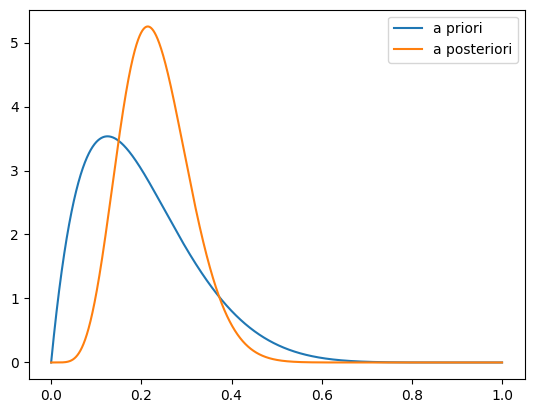

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

x = np.linspace(0, 1, 10000)

plt.plot(x, beta.pdf(x, 2, 8), label="a priori")
plt.plot(x, beta.pdf(x, 7, 23), label="a posteriori")

plt.legend()
plt.show()